# 곁(GYEOT) 모델링 v1 — 고령자 이상거래 탐지 + 재무 몬테카를로

이 노트북은 두 가지를 한다.

1. **이상거래 탐지**: 가상 고령자 거래 데이터를 만들고, 규칙(개인별 z-score) · Isolation Forest · 그래디언트 부스팅 세 모델을 비교한다. 평가는 정확도가 아니라 **"가족당 한 달 알림 N건으로 묶었을 때 사기를 몇 % 잡나"**로 한다. 알림이 자녀에게 가기 때문에 오탐 자체가 비용이다.
2. **재무 몬테카를로**: 창업계획서의 3년 재무 가정(해지율, 고객획득비용, 성장, B2B 계약)을 확률분포로 바꿔 **3년차 흑자 확률**과 **LTV/CAC 분포**를 본다.

주의: 실제 고령자 거래 데이터가 아니라 직접 설계한 가상 데이터다. 모델 성능 수치는 '데이터를 어떻게 만들었는가'에 크게 좌우되므로, 절대값보다 **모델 간 비교와 평가 프레임**에 의미가 있다.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from sklearn.inspection import permutation_importance

# 한글 폰트: 설치된 것 중 첫 번째 사용 (Mac: AppleGothic, Windows: Malgun Gothic)
for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
GREY, BLUE, LIGHT = "#9aa0a6", "#1a73e8", "#c6dafc"
COLORS = {"규칙(z-score)": GREY, "Isolation Forest": "#5f6368", "그래디언트 부스팅": BLUE}

## 1. 가상 거래 데이터 설계

| 구분 | 내용 |
| --- | --- |
| 평소 패턴 | 월 연금 입금, 공과금 3건, ATM 인출 월 2.5회, 지인 송금 월 1.5회, 카드 하루 0.5건. 개인마다 소득 규모(wealth)가 다름 |
| 정상이지만 튀는 거래 | 병원비 큰 결제, 경조사(새 계좌 송금), 자녀에게 큰 돈, 이사·수리(새 계좌 큰 송금), 명절 현금 여러 번 인출, 정상 대출(2%) |
| 사기 ① 사칭형 | 새 계좌로 몇 시간 안에 1~3회 송금, 금액 편차 큼 |
| 사기 ② 대면편취 | 1~3일 사이 현금 2~5회 인출 |
| 사기 ③ 대출사기 | 비대면 대출 입금 → 하루 안에 새 계좌 이체 또는 현금 인출 |
| 사기 ④ 주변인 착취 | 매주 중간 금액 송금이 수개월. **절반은 이미 알던 수취인** |

사기 에피소드는 전체 가구의 6%에 주입했다. 실제 발생률보다 높게 잡은 것은 학습·평가할 사례 수를 확보하기 위해서다.

In [2]:
"""가상 고령자 거래 데이터 생성기 (곁 GYEOT 이상거래 탐지용)

- 개인마다 '평소 패턴'(연금 입금, 공과금, 카드, ATM 인출, 지인 송금)을 따로 갖는다.
- 정상이지만 튀는 거래(병원비, 경조사 송금, 자녀 증여)를 섞어 오탐 상황을 만든다.
- 일부 개인에게 사기/착취 에피소드를 주입하고 거래 단위 라벨(is_fraud)과 episode_id를 붙인다.
"""
import numpy as np
import pandas as pd

TYPES = ["pension_in", "bill", "card", "atm", "transfer_out", "loan_in"]


def generate(n_people=1500, days=365, fraud_rate=0.06, seed=42):
    rng = np.random.default_rng(seed)
    start = pd.Timestamp("2025-01-01")
    rows = []
    ep_meta = []
    ep_id = 0

    def add(pid, t, typ, amt, payee, fraud=0, ep=-1):
        rows.append((pid, t, typ, float(round(amt, -2)), payee, fraud, ep))

    for pid in range(n_people):
        # 개인 특성: 소득·지출 규모
        wealth = rng.lognormal(0, 0.5)
        pension = 900_000 * wealth
        card_mu = np.log(25_000 * wealth)
        atm_mu = np.log(200_000 * wealth)
        tr_mu = np.log(150_000 * wealth)
        known = [f"P{pid}_k{i}" for i in range(rng.integers(2, 5))]
        active_h = rng.integers(8, 11)  # 주로 활동 시작 시각

        def ts(day, night=False):
            h = rng.integers(0, 6) if night else int(np.clip(rng.normal(active_h + 4, 3), 6, 21))
            return start + pd.Timedelta(days=int(day), hours=int(h), minutes=int(rng.integers(0, 60)))

        for m in range(12):
            d0 = m * 30
            add(pid, ts(d0 + 24), "pension_in", pension, "NPS")
            for b in range(3):  # 공과금·통신비·보험료
                add(pid, ts(d0 + 10 + b * 5), "bill", 60_000 * wealth * rng.uniform(0.6, 1.4), f"BILL{b}")
            for _ in range(rng.poisson(2.5)):
                add(pid, ts(d0 + rng.integers(0, 30)), "atm", rng.lognormal(atm_mu, 0.4), "ATM")
            for _ in range(rng.poisson(1.5)):
                add(pid, ts(d0 + rng.integers(0, 30)), "transfer_out", rng.lognormal(tr_mu, 0.6), rng.choice(known))
        for d in range(days):
            for _ in range(rng.poisson(0.5)):
                add(pid, ts(d), "card", rng.lognormal(card_mu, 0.8), f"M{rng.integers(0, 300)}")

        # 정상이지만 튀는 거래 (오탐 유발): 사기와 겉모습이 비슷한 진짜 거래
        for _ in range(rng.poisson(3)):
            kind = rng.choice(["hospital", "gift", "family", "big_new", "holiday_cash"],
                              p=[0.2, 0.25, 0.2, 0.15, 0.2])
            d = int(rng.integers(20, days - 3))
            if kind == "hospital":
                add(pid, ts(d), "card", rng.lognormal(np.log(1_500_000 * wealth), 0.5), "HOSP")
            elif kind == "gift":  # 경조사: 처음 보는 계좌로 송금
                add(pid, ts(d), "transfer_out", rng.choice([100_000, 200_000, 300_000, 500_000]), f"P{pid}_g{d}")
            elif kind == "family":  # 자녀에게 큰 돈
                add(pid, ts(d), "transfer_out", rng.lognormal(np.log(3_000_000 * wealth), 0.6), known[0])
            elif kind == "big_new":  # 이사·수리·중고거래: 처음 보는 계좌로 큰 돈
                add(pid, ts(d), "transfer_out", rng.lognormal(np.log(2_000_000 * wealth), 0.7), f"P{pid}_n{d}")
            else:  # 명절·경조사 현금: 이틀 동안 여러 번 인출
                for k in range(rng.integers(2, 4)):
                    add(pid, ts(d + k // 2), "atm", rng.lognormal(np.log(600_000 * wealth), 0.4), "ATM")
        if rng.random() < 0.02:  # 정상 대출 후 자녀에게 이체
            d = int(rng.integers(30, days - 2))
            loan = rng.choice([5_000_000, 10_000_000, 30_000_000])
            add(pid, ts(d), "loan_in", loan, "LOAN")
            add(pid, ts(d + 1), "transfer_out", loan * rng.uniform(0.5, 1.0), known[0])

        # 사기/착취 에피소드 주입 (4~12개월 사이)
        if rng.random() < fraud_rate:
            sc = rng.choice(["impersonation", "cash_pickup", "loan_scam", "exploitation"],
                            p=[0.35, 0.25, 0.2, 0.2])
            d = int(rng.integers(100, days - 40))
            ep_id += 1
            total = 0.0
            if sc == "impersonation":  # 가족·기관 사칭: 새 계좌로 몇 시간 안에 연속 송금 (금액 편차 큼)
                t0 = ts(d)
                for k in range(rng.integers(1, 4)):
                    a = rng.lognormal(np.log(2_500_000 * wealth), 0.9)
                    add(pid, t0 + pd.Timedelta(minutes=int(40 * k)), "transfer_out", a, f"F{ep_id}", 1, ep_id)
                    total += a
            elif sc == "cash_pickup":  # 대면편취: 1~3일 사이 현금 여러 번 인출
                for k in range(rng.integers(2, 6)):
                    a = rng.lognormal(np.log(700_000 * wealth), 0.5)
                    add(pid, ts(d + k // 2), "atm", a, "ATM", 1, ep_id)
                    total += a
            elif sc == "loan_scam":  # 비대면 대출 실행 → 하루 안에 새 계좌 이체 또는 현금 인출
                loan = rng.choice([5_000_000, 10_000_000, 20_000_000])
                t0 = ts(d)
                add(pid, t0, "loan_in", loan, "LOAN", 1, ep_id)
                if rng.random() < 0.5:
                    a = loan * rng.uniform(0.9, 1.0)
                    add(pid, t0 + pd.Timedelta(hours=int(rng.integers(1, 20))), "transfer_out", a, f"F{ep_id}", 1, ep_id)
                    total += a
                else:
                    for k in range(rng.integers(2, 5)):
                        a = rng.lognormal(np.log(1_000_000), 0.3)
                        add(pid, t0 + pd.Timedelta(hours=int(2 + 3 * k)), "atm", a, "ATM", 1, ep_id)
                        total += a
            else:  # 주변인 착취: 매주 중간 금액, 수개월. 절반은 이미 알던 수취인
                payee = f"F{ep_id}" if rng.random() < 0.5 else known[-1]
                for k in range(rng.integers(6, 14)):
                    a = rng.lognormal(np.log(250_000 * wealth), 0.4)
                    add(pid, ts(min(d + 7 * k, days - 1)), "transfer_out", a, payee, 1, ep_id)
                    total += a
            ep_meta.append((ep_id, pid, sc, total))

    df = pd.DataFrame(rows, columns=["pid", "ts", "type", "amount", "payee", "is_fraud", "episode"])
    df = df.sort_values(["pid", "ts"]).reset_index(drop=True)
    eps = pd.DataFrame(ep_meta, columns=["episode", "pid", "scenario", "loss"])
    return df, eps




In [3]:
df_raw, eps = generate(n_people=4000, seed=42)
print(f"거래 {len(df_raw):,}건, 가구 {df_raw.pid.nunique():,}, 사기 에피소드 {len(eps)}개")
print(eps.scenario.value_counts().rename("에피소드 수").to_frame().T)

거래 1,130,613건, 가구 4,000, 사기 에피소드 244개
scenario  impersonation  cash_pickup  loan_scam  exploitation
에피소드 수               82           58         56            48


## 2. 피처: '그 사람의 평소'와 비교

모든 피처는 **그 거래 이전 정보만** 써서 만든다(미래 정보 누수 방지). 핵심은 절대 금액이 아니라 개인 기준 대비 이탈 정도다. 100만 원 송금이 누군가에겐 평소이고 누군가에겐 이상이다.

- `z_type`: 같은 유형 과거 거래 대비 금액 z-score (로그 금액)
- `new_payee`: 처음 보는 수취인 송금 여부 / `payee_cnt_30d`: 최근 30일 같은 수취인 송금 횟수
- `n_out_24h`, `out_24h_ratio`: 직전 24시간 출금 건수, 평소 하루 출금 대비 배율
- `out_30d_ratio`: 최근 30일 출금이 평소 한 달 대비 몇 배인지 (느린 착취용)
- `loan_48h`: 48시간 안에 대출 입금이 있었는지

In [4]:
"""거래 단위 피처 생성. 모든 피처는 '그 거래 이전' 정보만 사용한다(누수 방지)."""
import numpy as np
import pandas as pd

OUT_TYPES = ["card", "atm", "transfer_out", "bill"]


def _window(keys, ts, vals, window_sec):
    """같은 key 그룹 안에서, 현재 행 '이전' 행들 중 [t-window, t] 구간의 vals 합 (현재 행 제외)."""
    order = np.lexsort((np.arange(len(ts)), ts, keys))
    k = keys[order].astype(np.int64)
    t = ts[order]
    v = vals[order].astype(float)
    comp = k * 10**9 + t
    left = np.searchsorted(comp, comp - window_sec, side="left")
    cs = np.concatenate([[0.0], np.cumsum(v)])
    pos = np.arange(len(t))
    res = cs[pos] - cs[left]
    out = np.empty(len(t))
    out[order] = res
    return out


def build_features(df):
    df = df.sort_values(["pid", "ts"]).reset_index(drop=True).copy()
    df["log_amt"] = np.log1p(df["amount"])
    df["is_out"] = df["type"].isin(OUT_TYPES).astype(int)
    df["out_amt"] = df["amount"] * df["is_out"]
    df["is_loan"] = (df["type"] == "loan_in").astype(int)
    df["hour"] = df["ts"].dt.hour
    df["night"] = (df["hour"] < 6).astype(int)

    # 1) 같은 유형 거래 대비 평소와 얼마나 다른가 (개인별 z-score)
    g = df.groupby(["pid", "type"])["log_amt"]
    df["past_mean"] = g.transform(lambda s: s.shift().expanding().mean())
    df["past_std"] = g.transform(lambda s: s.shift().expanding().std())
    df["past_n"] = df.groupby(["pid", "type"]).cumcount()
    df["z_type"] = (df["log_amt"] - df["past_mean"]) / df["past_std"].clip(lower=0.3)
    df["z_type"] = df["z_type"].where(df["past_n"] >= 3, 0.0).fillna(0.0)

    # 2) 처음 보는 수취인 / 최근 30일 그 수취인에게 보낸 횟수
    tr = df["type"] == "transfer_out"
    first_seen = df.groupby(["pid", "payee"]).cumcount() == 0
    df["new_payee"] = (first_seen & tr).astype(int)
    sec = ((df["ts"] - pd.Timestamp("2025-01-01")).dt.total_seconds()).to_numpy().astype(np.int64)
    pid = df["pid"].to_numpy()
    payee_key = df.groupby(["pid", "payee"]).ngroup().to_numpy()
    ones = np.ones(len(df))
    df["payee_cnt_30d"] = _window(payee_key, sec, ones, 30 * 86400) * tr

    # 3) 시간 창 집계: 직전 24시간 출금 건수·금액, 48시간 내 대출 입금, 30일 출금 합
    df["n_out_24h"] = _window(pid, sec, df["is_out"].to_numpy(), 86400)
    df["sum_out_24h"] = _window(pid, sec, df["out_amt"].to_numpy(), 86400) + df["out_amt"]
    df["loan_48h"] = (_window(pid, sec, df["is_loan"].to_numpy(), 2 * 86400) > 0).astype(int)
    df["sum_out_30d"] = _window(pid, sec, df["out_amt"].to_numpy(), 30 * 86400) + df["out_amt"]

    # 평소 하루 출금액 (지금까지 누적 출금 / 경과 일수)
    cum_out = df.groupby("pid")["out_amt"].cumsum() - df["out_amt"]
    days = (df["ts"] - df.groupby("pid")["ts"].transform("min")).dt.total_seconds() / 86400
    daily = (cum_out / days.clip(lower=1)).clip(lower=10_000)
    df["out_24h_ratio"] = df["sum_out_24h"] / daily
    df["out_30d_ratio"] = df["sum_out_30d"] / (daily * 30)

    for t in ["atm", "transfer_out", "card", "loan_in"]:
        df[f"t_{t}"] = (df["type"] == t).astype(int)
    return df


FEATURES = ["log_amt", "z_type", "new_payee", "payee_cnt_30d", "n_out_24h", "out_24h_ratio",
            "out_30d_ratio", "loan_48h", "t_atm", "t_transfer_out", "t_card", "t_loan_in"]


In [5]:
df = build_features(df_raw)
ev = df[df.ts >= pd.Timestamp("2025-04-01")].copy()   # 첫 3개월은 '평소'를 배우는 기간으로 제외
print(f"평가 대상 거래 {len(ev):,}건, 사기 거래 비율 {ev.is_fraud.mean():.3%}")

평가 대상 거래 850,958건, 사기 거래 비율 0.118%


## 3. 세 모델 비교 (가구 단위 5-fold 교차검증)

같은 가구의 거래가 학습과 평가에 동시에 들어가지 않도록 **가구 단위로 fold를 나눈다**. 모든 가구의 거래가 한 번씩 '처음 보는 가구'로 평가된다.

- **규칙(z-score)**: `z_type + 2×새 수취인 + 3×대출 직후 + 0.3×log(24시간 출금 배율)`. 라벨 없이 바로 쓸 수 있는 출발점
- **Isolation Forest**: 라벨 없이 '드문 거래'를 찾는 비지도 모델
- **그래디언트 부스팅**: 라벨로 학습하는 지도 모델 (sklearn HistGradientBoosting, 클래스 가중치 균형)

In [6]:
ev["s_rule"] = ev.z_type.clip(lower=0) + 2*ev.new_payee + 3*ev.loan_48h + 0.3*np.log1p(ev.out_24h_ratio)
ev["s_iso"] = np.nan; ev["s_hgb"] = np.nan
gkf = GroupKFold(n_splits=5)
for k, (tr_i, te_i) in enumerate(gkf.split(ev, groups=ev.pid)):
    tr, te = ev.iloc[tr_i], ev.iloc[te_i]
    iso = IsolationForest(n_estimators=200, random_state=k).fit(tr[FEATURES].sample(200_000, random_state=k))
    ev.iloc[te_i, ev.columns.get_loc("s_iso")] = -iso.score_samples(te[FEATURES])
    hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=k)
    hgb.fit(tr[FEATURES], tr.is_fraud)
    ev.iloc[te_i, ev.columns.get_loc("s_hgb")] = hgb.predict_proba(te[FEATURES])[:, 1]
MODELS = {"규칙(z-score)": "s_rule", "Isolation Forest": "s_iso", "그래디언트 부스팅": "s_hgb"}
pd.Series({m: average_precision_score(ev.is_fraud, ev[s]) for m, s in MODELS.items()}, name="PR-AUC (거래 단위)").round(3).to_frame().T

,규칙(z-score),Isolation Forest,그래디언트 부스팅
PR-AUC (거래 단위),0.029,0.064,0.342


### 평가 기준: 알림 예산

PR-AUC는 거래 하나하나를 맞히는지를 본다. 하지만 가족 입장에서는 **사기 사건(에피소드)을 한 번이라도 알려줬는지**가 중요하다. 그래서 '가구당 한 달 알림 수'를 예산으로 정해 놓고, 점수 상위 거래부터 알림을 보낸다고 가정한다. 그다음 에피소드 탐지율을 잰다.

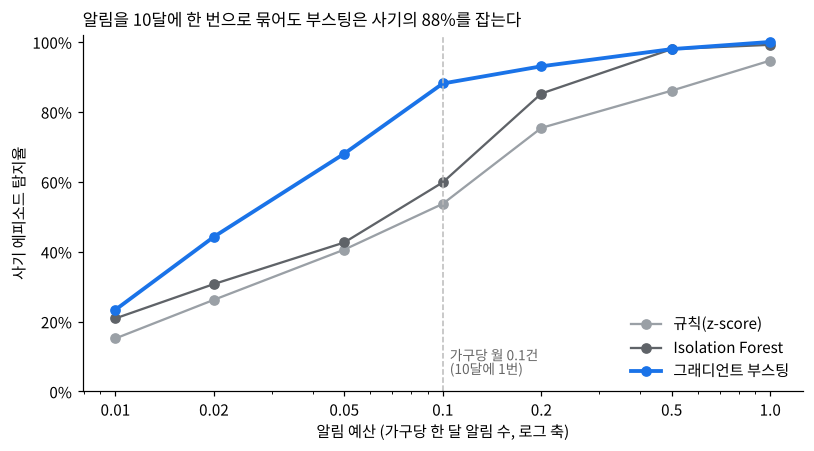

예산,0.01,0.02,0.05,0.10,0.20,0.50,1.00
모델,,,,,,,
Isolation Forest,0.21,0.31,0.43,0.60,0.85,0.98,0.99
규칙(z-score),0.15,0.26,0.41,0.54,0.75,0.86,0.95
그래디언트 부스팅,0.23,0.44,0.68,0.88,0.93,0.98,1.00


In [7]:
N_FAM, MONTHS = ev.pid.nunique(), 9

def evaluate(score, budget):
    k = int(budget * N_FAM * MONTHS)
    thr = ev[score].nlargest(k).min()
    al = ev[ev[score] >= thr]
    caught = set(al.loc[al.is_fraud == 1, "episode"])
    return al, caught

budgets = [0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
rows = []
for m, s in MODELS.items():
    for b in budgets:
        al, caught = evaluate(s, b)
        rows.append(dict(모델=m, 예산=b, 탐지율=len(caught)/len(eps), 정밀도=al.is_fraud.mean()))
curve = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in MODELS:
    c = curve[curve.모델 == m]
    ax.plot(c.예산, c.탐지율, marker="o", color=COLORS[m], lw=2.5 if m == "그래디언트 부스팅" else 1.5, label=m)
ax.axvline(0.1, color="#bbb", ls="--", lw=1); ax.text(0.105, 0.05, "가구당 월 0.1건\n(10달에 1번)", color="#666", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(budgets); ax.set_xticklabels([str(b) for b in budgets])
ax.set_ylim(0, 1.02); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_xlabel("알림 예산 (가구당 한 달 알림 수, 로그 축)"); ax.set_ylabel("사기 에피소드 탐지율")
b01 = curve[(curve.예산 == 0.1)].set_index("모델").탐지율
ax.set_title(f"알림을 10달에 한 번으로 묶어도 부스팅은 사기의 {b01['그래디언트 부스팅']:.0%}를 잡는다", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
curve.pivot(index="모델", columns="예산", values="탐지율").round(2)

### 시나리오별로 보면 약점이 보인다

예산을 **가구당 월 0.1건**으로 고정하고 사기 유형별 탐지율을 본다.

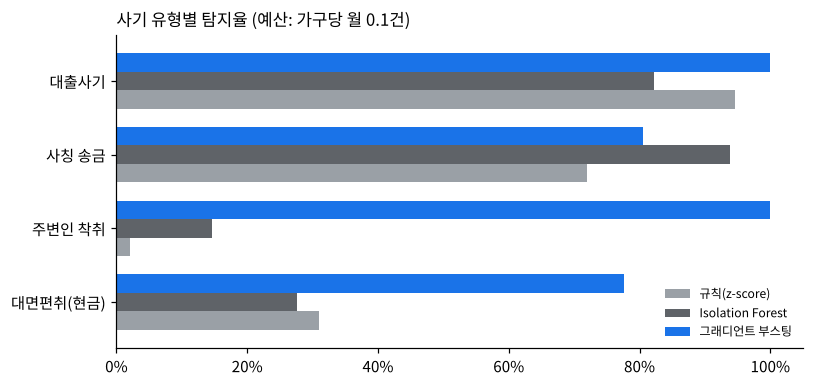

,규칙(z-score),Isolation Forest,그래디언트 부스팅
scenario,,,
대면편취(현금),0.31,0.28,0.78
주변인 착취,0.02,0.15,1.00
사칭 송금,0.72,0.94,0.80
대출사기,0.95,0.82,1.00


In [8]:
B = 0.1
rows = []
for m, s in MODELS.items():
    _, caught = evaluate(s, B)
    r = eps.assign(c=eps.episode.isin(caught)).groupby("scenario").c.mean()
    rows.append(r.rename(m))
by_sc = pd.DataFrame(rows).T
by_sc.index = by_sc.index.map({"impersonation": "사칭 송금", "cash_pickup": "대면편취(현금)",
                               "loan_scam": "대출사기", "exploitation": "주변인 착취"})
ax = by_sc.plot.barh(figsize=(7.5, 3.6), color=[COLORS[m] for m in by_sc.columns], width=0.75)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set_xlim(0, 1.05); ax.set_ylabel("")
ax.set_title(f"사기 유형별 탐지율 (예산: 가구당 월 {B}건)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
by_sc.round(2)

### 언제 잡느냐: 대응 지연과 피해 차단액

에피소드를 '결국 잡았다'와 '돈이 나가기 전에 잡았다'는 다르다. 첫 알림 이후 가족이 **지연 시간 L 안에** 대응해 남은 사기 출금을 막는다고 가정하고, 전체 사기 출금액 중 막을 수 있는 비율을 계산한다.

이 계산이 사업 구조를 바꾼다. 마이데이터의 정기 전송은 **기본 주 1회**다. 앱을 열 때마다 조회하는 방식도 실시간은 아니다. 그래서 B2C 앱만으로는 지연이 길어진다. 실시간 차단을 하려면 금융기관 내부에 엔진을 넣는 B2B 트랙이 필요하다.

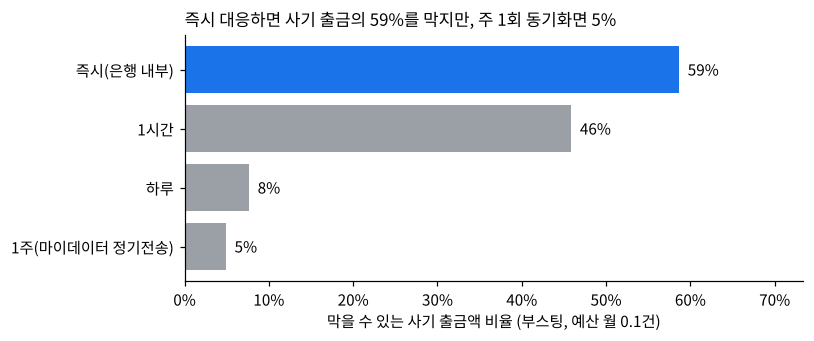

즉시(은행 내부)         0.587
1시간               0.459
하루                0.077
1주(마이데이터 정기전송)    0.049
dtype: float64

In [9]:
out_fraud = ev[(ev.is_fraud == 1) & (ev.type != "loan_in")]
total_loss = out_fraud.amount.sum()

def prevented_share(score, budget, lag_hours):
    al, _ = evaluate(score, budget)
    first = al[al.is_fraud == 1].groupby("episode").ts.min()
    x = out_fraud.join(first.rename("first_alert"), on="episode")
    blocked = x[x.ts > x.first_alert + pd.Timedelta(hours=lag_hours)].amount.sum()
    return blocked / total_loss

lags = {"즉시(은행 내부)": 0, "1시간": 1, "하루": 24, "1주(마이데이터 정기전송)": 168}
prev = pd.Series({k: prevented_share("s_hgb", 0.1, h) for k, h in lags.items()})
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.barh(prev.index[::-1], prev.values[::-1], color=[BLUE if i == 0 else GREY for i in range(len(prev))][::-1])
for b_, v in zip(bars, prev.values[::-1]):
    ax.text(v + 0.01, b_.get_y() + b_.get_height()/2, f"{v:.0%}", va="center", fontsize=10)
ax.set_xlim(0, max(prev) * 1.25); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title(f"즉시 대응하면 사기 출금의 {prev.iloc[0]:.0%}를 막지만, 주 1회 동기화면 {prev.iloc[-1]:.0%}", loc="left", fontsize=11)
ax.set_xlabel("막을 수 있는 사기 출금액 비율 (부스팅, 예산 월 0.1건)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
prev.round(3)

### 무엇이 판단을 이끄나 (순열 중요도)

마지막 fold의 부스팅 모델로 계산했다. 사기 거래를 최대한 포함한 표본을 쓴다.

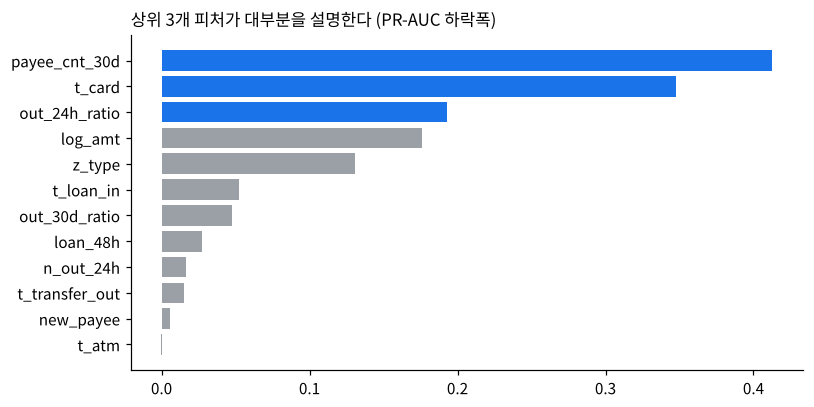

In [10]:
samp = pd.concat([te[te.is_fraud == 1], te[te.is_fraud == 0].sample(20_000, random_state=0)])
pi = permutation_importance(hgb, samp[FEATURES], samp.is_fraud, scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(imp.index, imp.values, color=[BLUE if i >= len(imp)-3 else GREY for i in range(len(imp))])
ax.set_title("상위 3개 피처가 대부분을 설명한다 (PR-AUC 하락폭)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 4. 재무 몬테카를로: 3년차 흑자 확률

창업계획서의 점추정을 분포로 바꾼다. **기준 시나리오를 넣으면 계획서 숫자가 그대로 재현되는지** 먼저 확인한다.

| 변수 | 계획서 값 | 분포(가정) | 근거 |
| --- | --- | --- | --- |
| 연 해지율 | 25% | Beta(6,14), 평균 30% | 구독 서비스는 초기 해지가 높음. 보수적으로 상향 |
| 고객획득비용(CAC) | 4만 원 | 로그정규, 중앙값 7만 원 | 4만 원은 낙관적. 40~50대 대상 핀테크 광고 단가 반영 |
| 신규 유료 가구 | 연 2,000 / 13,500 / 38,750 | 계획 × 로그정규(0, 0.4) 배수 | 실행 불확실성 |
| B2B 계약 기관 | 2년차 3곳, 3년차 8곳 | 2년차 포아송(3), 3년차 +포아송(5) | 금융기관 영업 주기 |
| 기관당 연 계약액 | 2~2.5억 | 균등(1.5억, 3억) | |
| 가구당 데이터 비용 | 월 800원 | 균등(600, 1,200원) | |
| 인건비·기타 고정비 | 계획서 그대로 | 고정 | |

In [11]:
PRICE = 7_900
PLAN_NEW = np.array([2_000, 13_500, 38_750])
PEOPLE = np.array([4.2e8, 9.8e8, 19.6e8]); OTHER = np.array([2e8, 3e8, 5e8])
REFERRAL = np.array([0, 0.5e8, 2e8]); B2B_Y1 = 0.3e8

def simulate(churn, cac, mult, n2, n3, contract, data_cost):
    subs, rev, cost = 0.0, [], []
    n_inst = [0, n2, n3]
    for t in range(3):
        new = PLAN_NEW[t] * mult
        end = subs * (1 - churn) + new
        avg = (subs + end) / 2
        b2b = B2B_Y1 if t == 0 else n_inst[t] * (contract[t - 1] if np.ndim(contract) else contract)
        r = avg * PRICE * 12 + b2b + REFERRAL[t] * mult
        c = PEOPLE[t] + OTHER[t] + new * cac + avg * data_cost * 12
        rev.append(r); cost.append(c); subs = end
    rev, cost = np.array(rev), np.array(cost)
    return rev, rev - cost

# 기준 시나리오 = 계획서 값 (해지 25%, CAC 4만, 배수 1, 기관 3·8곳, 계약액 2억·2.5억, 데이터 800원)
r, p = simulate(0.25, 40_000, 1.0, 3, 8, (2e8, 2.5e8), 800)
print("매출(억):", (r/1e8).round(2), " 계획서: 1.25, 14.56, 52.81")
print("영업손익(억):", (p/1e8).round(2), " 계획서: -5.85, -4.46, +9.59")

매출(억): [ 1.25 14.56 52.81]  계획서: 1.25, 14.56, 52.81
영업손익(억): [-5.85 -4.46  9.59]  계획서: -5.85, -4.46, +9.59


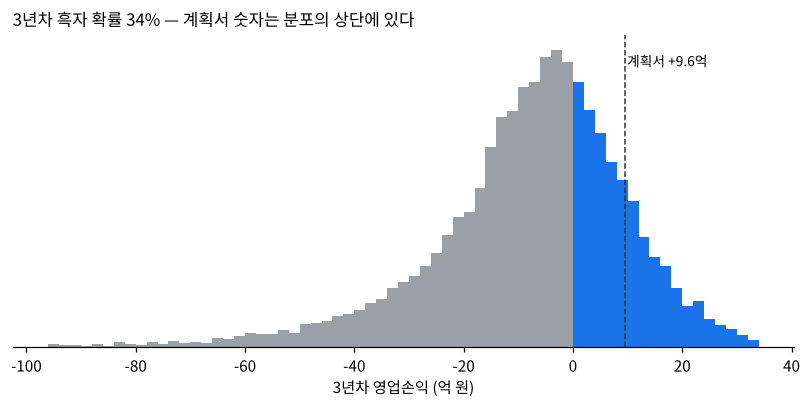

,Y3_이익,누적적자_최대,LTV_CAC
10%,-31.8,7.1,2.0
50%,-5.8,20.5,4.2
90%,12.3,57.5,9.4


In [12]:
rng = np.random.default_rng(7)
N = 20_000
draw = pd.DataFrame({
    "해지율": rng.beta(6, 14, N),
    "CAC": rng.lognormal(np.log(70_000), 0.5, N),
    "성장배수": rng.lognormal(0, 0.4, N),
    "기관_2년차": rng.poisson(3, N),
    "계약액": rng.uniform(1.5e8, 3e8, N),
    "데이터비용": rng.uniform(600, 1_200, N),
})
draw["기관_3년차"] = draw["기관_2년차"] + rng.poisson(5, N)
res = [simulate(d.해지율, d.CAC, d.성장배수, d.기관_2년차, d.기관_3년차, d.계약액, d.데이터비용) for d in draw.itertuples()]
draw["Y3_이익"] = [p[2] / 1e8 for _, p in res]
draw["누적적자_최대"] = [-min(0, np.cumsum(p).min()) / 1e8 for _, p in res]
draw["LTV"] = (PRICE - draw.데이터비용) * 12 / draw.해지율
draw["LTV_CAC"] = draw.LTV / draw.CAC
p_profit = (draw.Y3_이익 > 0).mean()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bins = np.arange(np.floor(draw.Y3_이익.quantile(.005)), draw.Y3_이익.quantile(.995) + 2, 2)
ax.hist(draw.Y3_이익[draw.Y3_이익 <= 0], bins=bins, color=GREY)
ax.hist(draw.Y3_이익[draw.Y3_이익 > 0], bins=bins, color=BLUE)
ax.axvline(9.59, color="#333", ls="--", lw=1); ax.text(9.9, ax.get_ylim()[1]*0.9, "계획서 +9.6억", fontsize=9)
ax.set_xlabel("3년차 영업손익 (억 원)"); ax.set_yticks([])
ax.set_title(f"3년차 흑자 확률 {p_profit:.0%} — 계획서 숫자는 분포의 상단에 있다", loc="left", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False); plt.tight_layout(); plt.show()
draw[["Y3_이익", "누적적자_최대", "LTV_CAC"]].describe(percentiles=[.1, .5, .9]).loc[["10%", "50%", "90%"]].round(1)

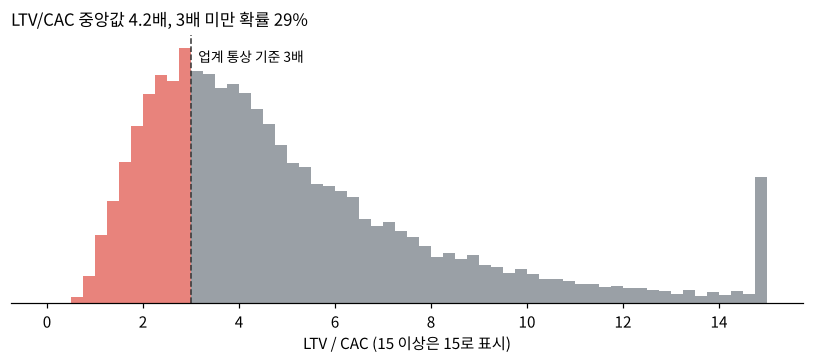

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = draw.LTV_CAC.clip(upper=15)
ax.hist(x[x < 3], bins=np.arange(0, 15.25, 0.25), color="#d93025", alpha=0.6)
ax.hist(x[x >= 3], bins=np.arange(0, 15.25, 0.25), color=GREY)
ax.axvline(3, color="#333", ls="--", lw=1); ax.text(3.15, ax.get_ylim()[1]*0.9, "업계 통상 기준 3배", fontsize=9)
ax.set_xlabel("LTV / CAC (15 이상은 15로 표시)"); ax.set_yticks([])
ax.set_title(f"LTV/CAC 중앙값 {draw.LTV_CAC.median():.1f}배, 3배 미만 확률 {(draw.LTV_CAC < 3).mean():.0%}", loc="left", fontsize=11)
ax.spines[["top", "right", "left"]].set_visible(False); plt.tight_layout(); plt.show()

### 무엇이 흑자를 좌우하나

각 입력을 표준화해 3년차 이익에 회귀한 계수다. '입력이 1 표준편차 움직일 때 이익이 몇 억 변하나'로 읽는다.

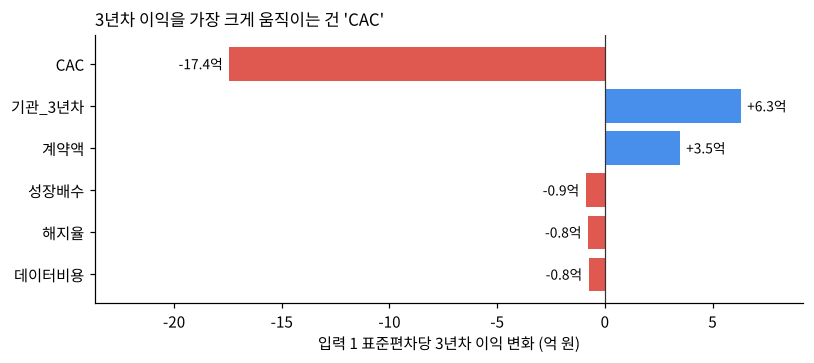

데이터비용     -0.75
해지율       -0.78
성장배수      -0.89
계약액        3.48
기관_3년차     6.31
CAC      -17.44
dtype: float64

In [14]:
inputs = ["해지율", "CAC", "성장배수", "기관_3년차", "계약액", "데이터비용"]
Z = (draw[inputs] - draw[inputs].mean()) / draw[inputs].std()
coef = pd.Series(np.linalg.lstsq(np.c_[np.ones(N), Z], draw.Y3_이익, rcond=None)[0][1:], index=inputs).sort_values(key=abs)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(coef.index, coef.values, color=[BLUE if v > 0 else "#d93025" for v in coef.values], alpha=0.8)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlim(min(coef.min(), 0) * 1.3 - 1, max(coef.max(), 0) * 1.3 + 1)
for i, v in enumerate(coef.values):
    ax.text(v + (0.3 if v > 0 else -0.3), i, f"{v:+.1f}억", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.set_title(f"3년차 이익을 가장 크게 움직이는 건 '{coef.index[-1]}'", loc="left", fontsize=11)
ax.set_xlabel("입력 1 표준편차당 3년차 이익 변화 (억 원)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
coef.round(2)

**읽는 법**: 성장배수가 음수인 게 직관과 반대다. 이유는 신규 가입자가 들어온 해에 CAC는 전액 나가는데, 구독료는 평균 반년 치만 들어오기 때문이다(연 9.5만 원의 절반 ≈ 4.7만 원 < CAC 중앙값 7만 원). 그래서 **빨리 클수록 3년차 이익은 오히려 줄어든다.** 가입자 단위로는 LTV/CAC 중앙값이 4배 넘게 남는 사업이어서, 이건 회수 시점의 문제다. 결론적으로 사업을 가르는 변수는 CAC 하나다. 베타에서 가장 먼저 재야 할 숫자다.

## 5. 다음에 할 것

- **탐지 모델**: 주변인 착취는 규칙(2%)과 Isolation Forest(15%)로는 거의 못 잡고, 라벨로 학습한 부스팅만 잡았다. 라벨이 없는 출시 초기에는 이게 약점이다. 수취인 단위 추세 피처(최근 4주 송금액 기울기)를 넣어 비지도 단계에서도 잡히게 만든다.
- **앙상블**: 사칭 송금은 Isolation Forest(94%)가 부스팅(80%)보다 잘 잡았다. 처음 보는 유형의 이상에는 비지도 모델이 강하다는 뜻이다. 두 점수를 순위 평균으로 합친 앙상블을 비교한다.
- **평가**: 실제 발생률(가구당 연 0.5% 안팎으로 가정)로 다운샘플링해 정밀도를 다시 계산한다. 이번 데이터는 사기를 6%로 부풀렸으므로 정밀도가 과대평가돼 있다.
- **데이터**: Kaggle PaySim, IEEE-CIS로 같은 파이프라인을 돌려 가상 데이터 의존도를 낮춘다.
- **재무**: CAC와 해지율은 베타 테스트 실측값으로 교체한다. 위 민감도 분석이 '무엇부터 검증할지'의 순서다.